In [1]:
import pandas as pd
import numpy as np

# Génération des données
np.random.seed(42)
n_customers = 1000

data = {
    'customer_id': range(n_customers),
    'age': np.random.normal(45, 15, n_customers).astype(int),
    'annual_income': np.random.lognormal(mean=4.0, sigma=0.5, size=n_customers),
    'spending_score': np.random.randint(1, 101, n_customers),
    'membership_years': np.random.exponential(5, n_customers).astype(int),
    'churn': np.random.binomial(1, 0.2, n_customers)
}

df = pd.DataFrame(data)
df['age'] = np.clip(df['age'], 18, 80)
df['annual_income'] = np.round(df['annual_income'] * 10, 2)
df['membership_years'] = np.clip(df['membership_years'], 0, 20)

In [2]:
print(df.head())
corr=df['annual_income'].corr(df['spending_score'])
print(corr)

   customer_id  age  annual_income  spending_score  membership_years  churn
0            0   52        1099.12              30                 1      0
1            1   42         866.88              95                 3      0
2            2   54         562.51              75                 3      0
3            3   67         395.09              99                 2      0
4            4   41         774.10              72                 2      0
-0.0001975036301724513


In [3]:
churn_df=df["age"].loc[df["churn"]==1]
non_churn_df=df["age"].loc[df["churn"]==0]

In [4]:
from scipy.stats import ttest_ind


# Effectuer le test t de Student pour comparer les moyennes des âges entre les deux groupes
statistique, p_value = ttest_ind(churn_df, non_churn_df)

# Interprétation du résultat
alpha = 0.05  # Seuil de significativité
if p_value < alpha:
    print("Il y a une différence significative d'âge entre les clients qui churnent et ceux qui restent (p={:.4f}).".format(p_value))
else:
    print("Aucune différence significative n'est observée (p={:.4f}).".format(p_value))


Aucune différence significative n'est observée (p=0.8189).


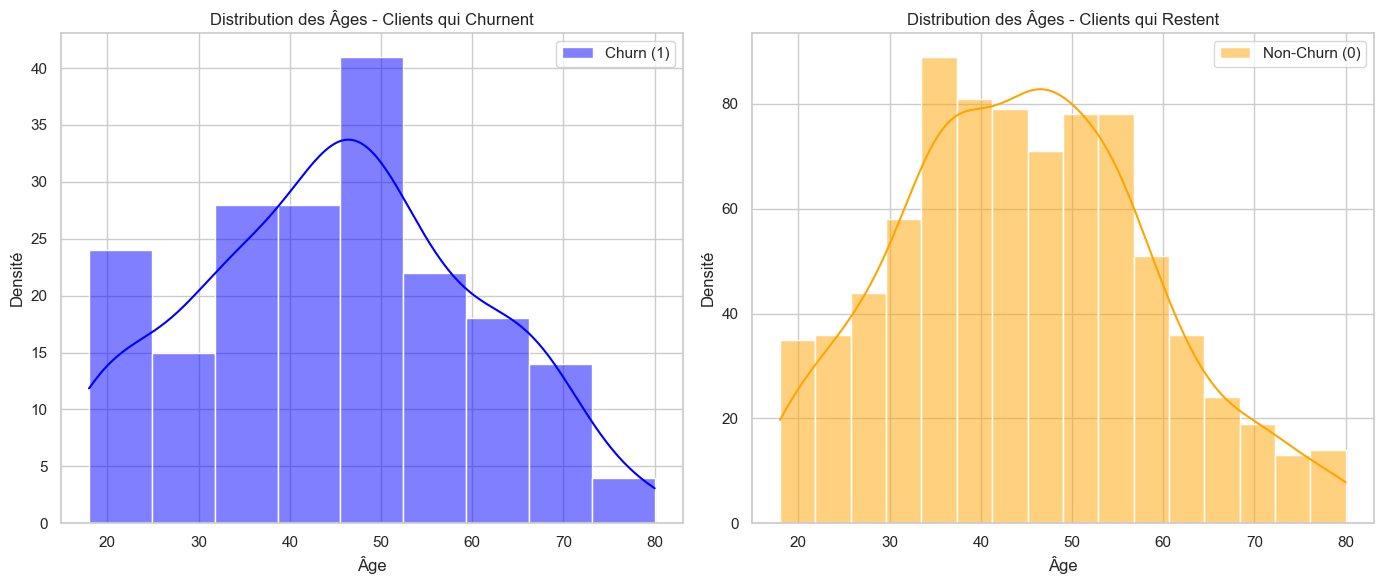

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

# Configuration du style de la visualisation
sns.set(style="whitegrid")

# Création d'une figure avec deux sous-graphiques
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Tracé de la distribution des âges pour les clients qui churnent
sns.histplot(churn_df, kde=True, ax=axes[0], color="blue", label="Churn (1)")
axes[0].set_title("Distribution des Âges - Clients qui Churnent")
axes[0].set_xlabel("Âge")
axes[0].set_ylabel("Densité")
axes[0].legend()

# Tracé de la distribution des âges pour les clients qui restent
sns.histplot(non_churn_df, kde=True, ax=axes[1], color="orange", label="Non-Churn (0)")
axes[1].set_title("Distribution des Âges - Clients qui Restent")
axes[1].set_xlabel("Âge")
axes[1].set_ylabel("Densité")
axes[1].legend()

# Ajustement de l'espacement entre les sous-graphiques
plt.tight_layout()

# Affichage de la figure
plt.show()


In [5]:
def palindrome(s):
    left, right = 0, len(s)-1
    while right > left:
        if s[left].lower()==s[right].lower():
            left += 1
            right -= 1

        else :
            return False
    
    return True

In [6]:
s='kayakl'
print(palindrome(s))

False
